In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
# from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
# from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score,accuracy_score,recall_score,f1_score,confusion_matrix

In [2]:
data = pd.read_csv("loan approval data.csv").copy()

# Handle Missing Values

In [3]:
cat_cols = data.select_dtypes(include=["object"]).columns
num_cols = data.select_dtypes(include=["number"]).columns

In [4]:
num_imp = SimpleImputer(strategy="mean")
data[num_cols] = num_imp.fit_transform(data[num_cols])

In [5]:
cat_imp = SimpleImputer(strategy="most_frequent")
data[cat_cols] = cat_imp.fit_transform(data[cat_cols])

# EDA- Exploratory data Analysis

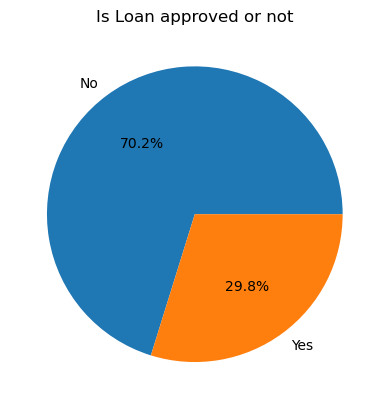

In [6]:
# how balance our classes are:
classes_cont = data["Loan_Approved"].value_counts()
plt.pie(classes_cont, labels=["No","Yes"], autopct="%1.1f%%")
plt.title("Is Loan approved or not")
plt.show()

[Text(0, 0, '621'), Text(0, 0, '379')]

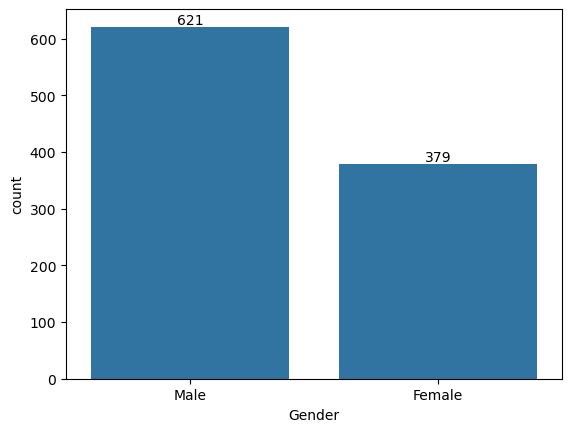

In [7]:
# categorical plot
cat_cnt = data["Gender"].value_counts()
ax = sns.barplot(cat_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

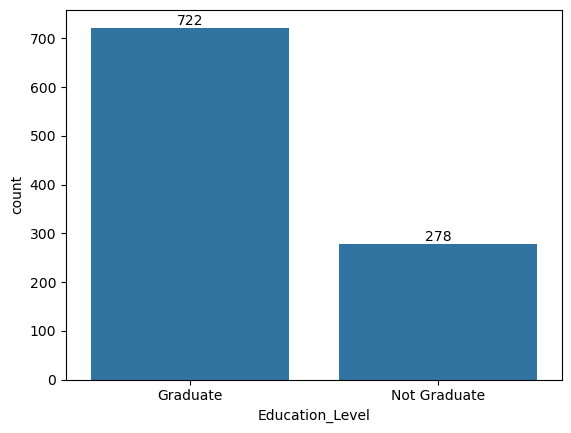

In [8]:
# categorical plot
edu_cnt = data["Education_Level"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '252'),
 Text(0, 0, '199'),
 Text(0, 0, '190'),
 Text(0, 0, '181'),
 Text(0, 0, '178')]

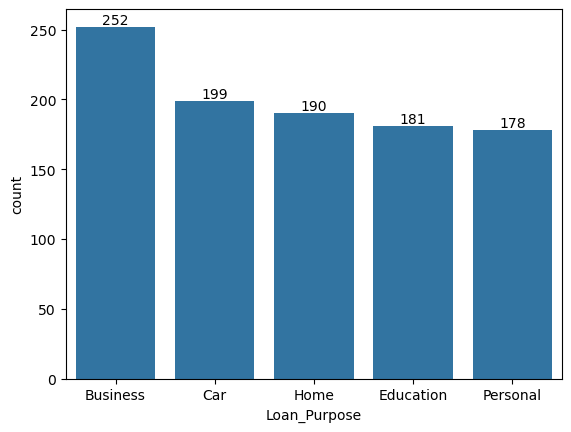

In [10]:
# Loan_Purpose
Loan_Purpose = data["Loan_Purpose"].value_counts()
ax = sns.barplot(Loan_Purpose)
ax.bar_label(ax.containers[0])

[Text(0, 0, '517'), Text(0, 0, '294'), Text(0, 0, '189')]

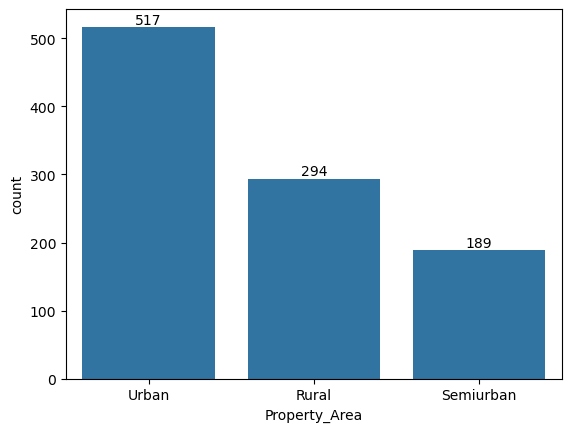

In [11]:
# Property_Area
Property_Area = data["Property_Area"].value_counts()
ax = sns.barplot(Property_Area)
ax.bar_label(ax.containers[0])

[Text(0, 0, '643'), Text(0, 0, '357')]

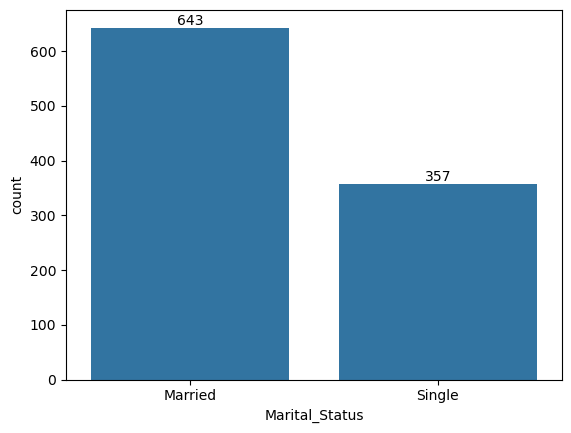

In [12]:
# Marital_Status
Marital_Status = data["Marital_Status"].value_counts()
ax = sns.barplot(Marital_Status)
ax.bar_label(ax.containers[0])

[Text(0, 0, '515'), Text(0, 0, '213'), Text(0, 0, '182'), Text(0, 0, '90')]

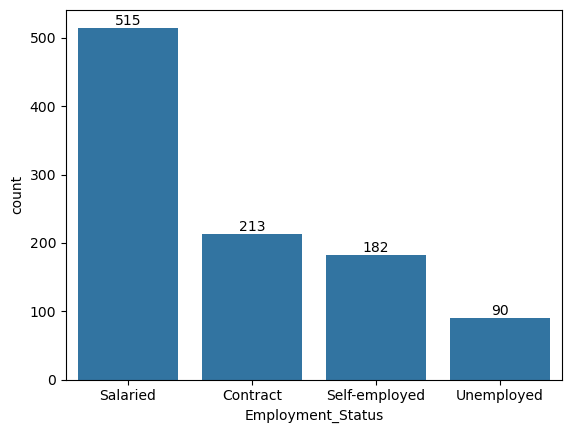

In [13]:
# Employment_Status
Employment_Status = data["Employment_Status"].value_counts()
ax = sns.barplot(Employment_Status)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

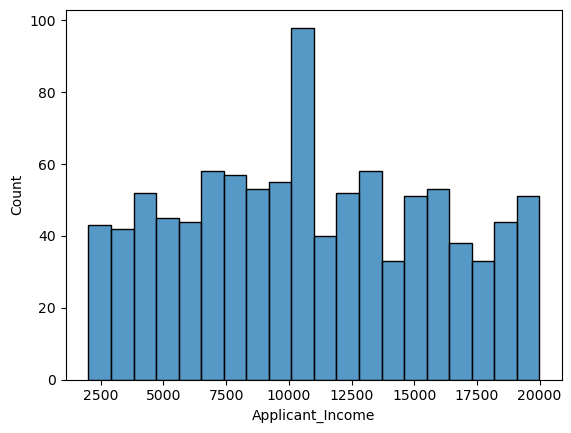

In [14]:
# analyze income
sns.histplot(
    data=data,
    x="Applicant_Income",
    bins=20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

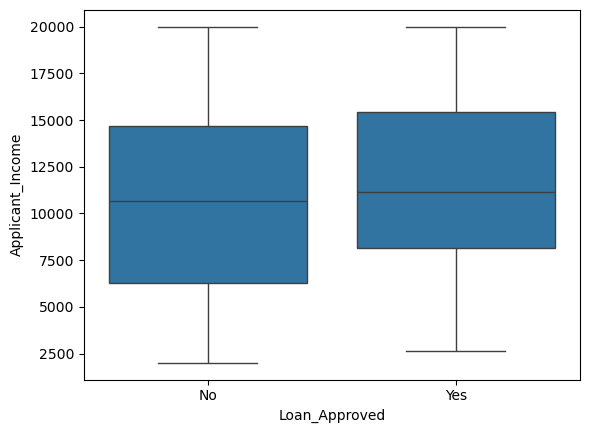

In [16]:
# Detect outlayer
sns.boxplot(x="Loan_Approved", y="Applicant_Income", data=data)

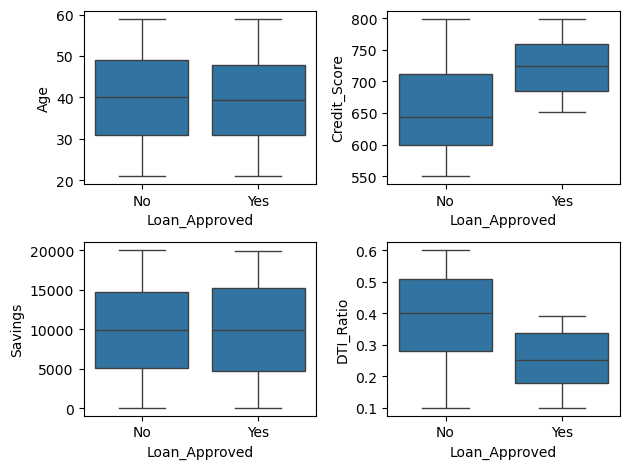

In [17]:
fig,axes = plt.subplots(2,2)

sns.boxplot(ax = axes[0,0],x="Loan_Approved", y="Age", data=data)
sns.boxplot(ax = axes[0,1],x="Loan_Approved", y="Credit_Score", data=data)
sns.boxplot(ax = axes[1,0],x="Loan_Approved", y="Savings", data=data)
sns.boxplot(ax = axes[1,1],x="Loan_Approved", y="DTI_Ratio", data=data)
plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

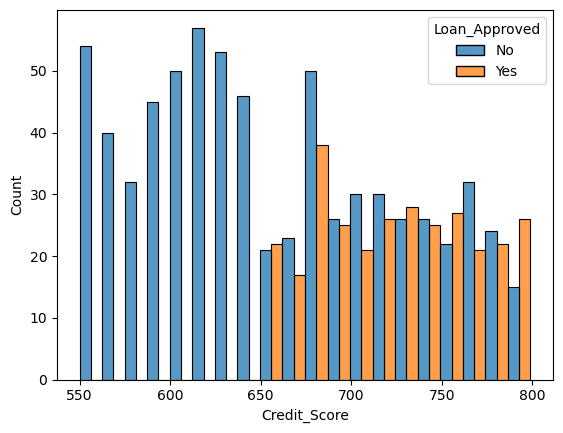

In [18]:
# Loan Approval
sns.histplot(
    data=data,
    x="Credit_Score",
    hue ="Loan_Approved",
    bins=20,
    multiple="dodge"
)